In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Folder containing one .jsonl file per NTP server
DATA_DIR = Path('../Desktop/Dataset/20261102_132633_3Hours')
WINDOW = 10  # rolling median window (samples)
TZ = 'Europe/Berlin'


def load(path):
    df = pd.read_json(path, lines=True)
    df['time'] = pd.to_datetime(df['timestamp_ms'], unit='ms', utc=True).dt.tz_convert(TZ)
    return df.sort_values('time').reset_index(drop=True)

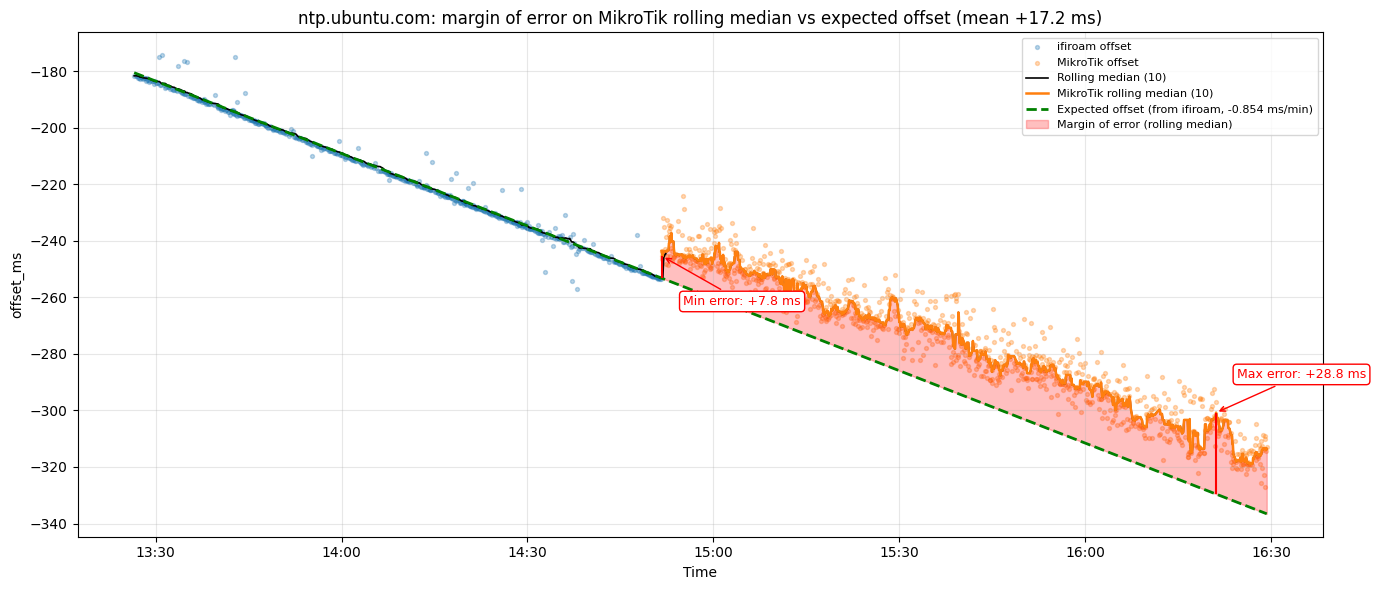

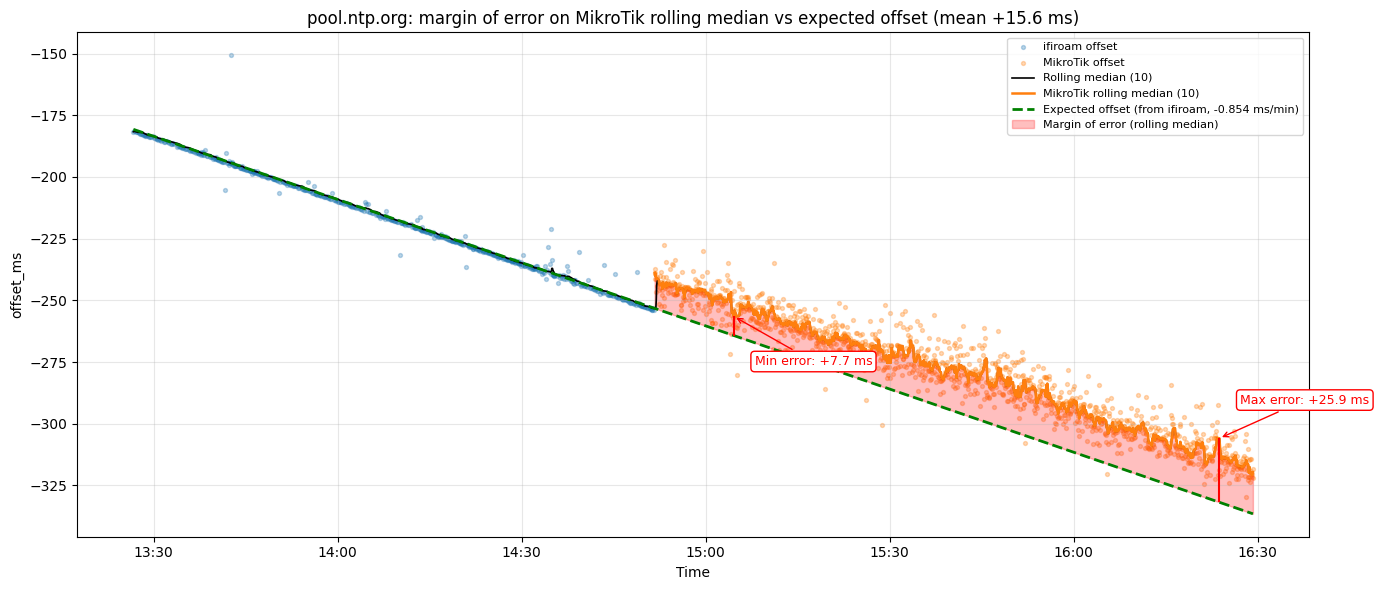

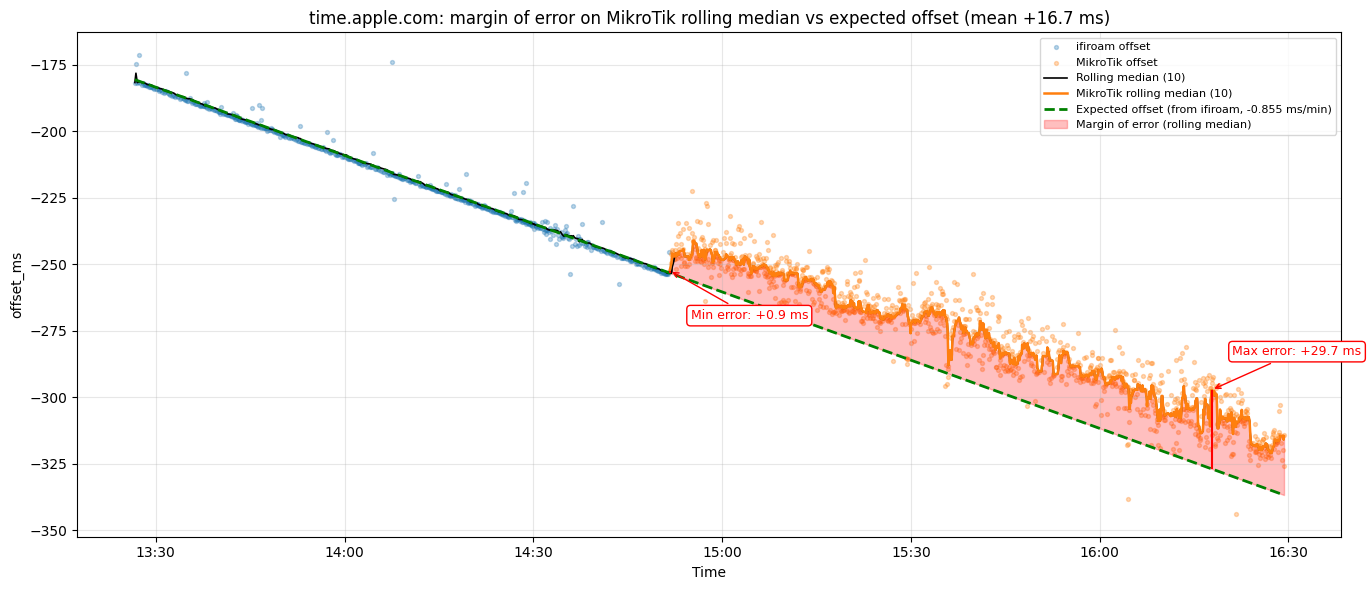

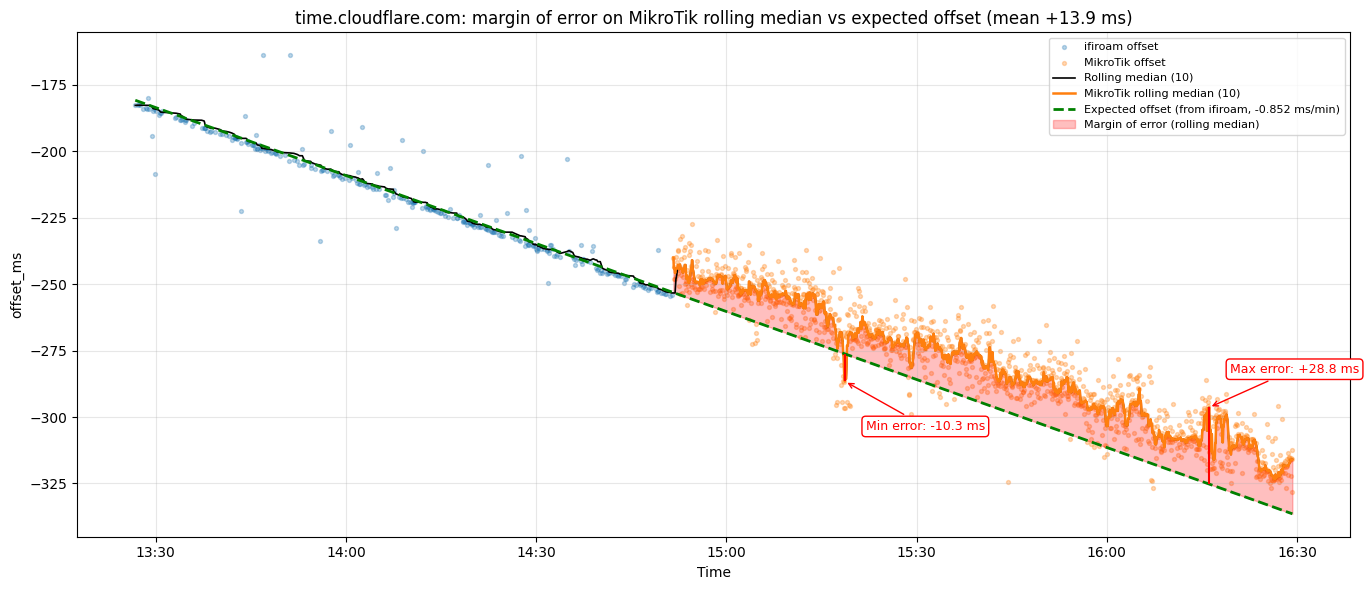

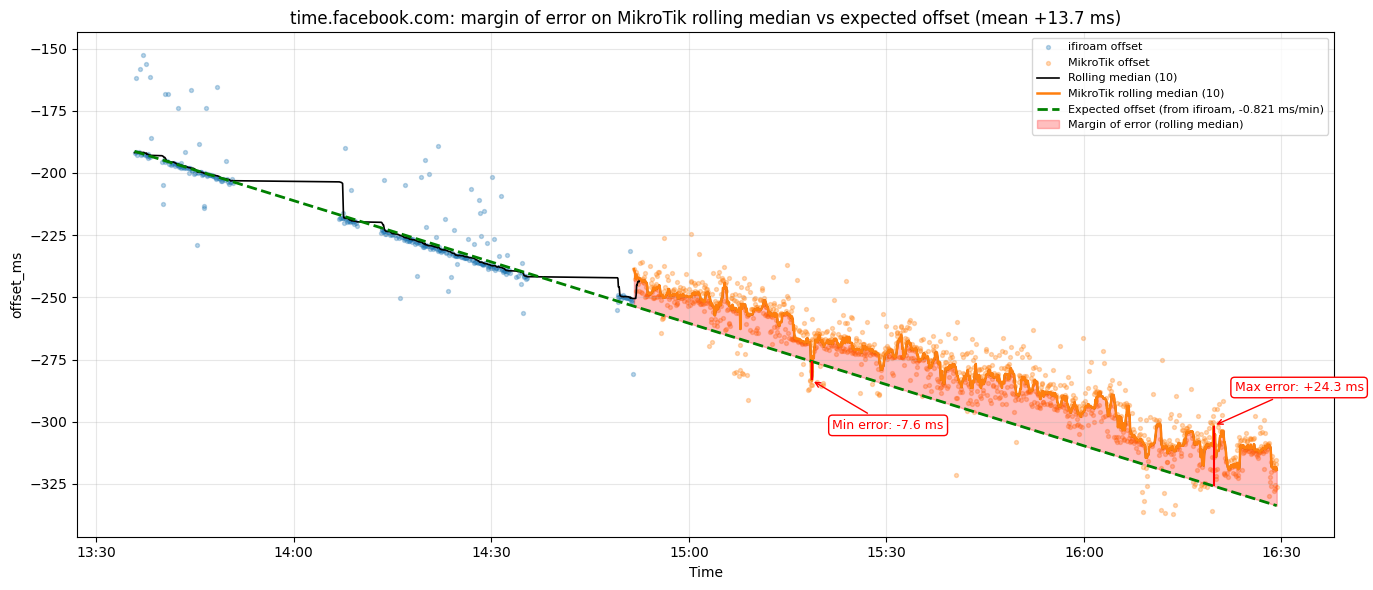

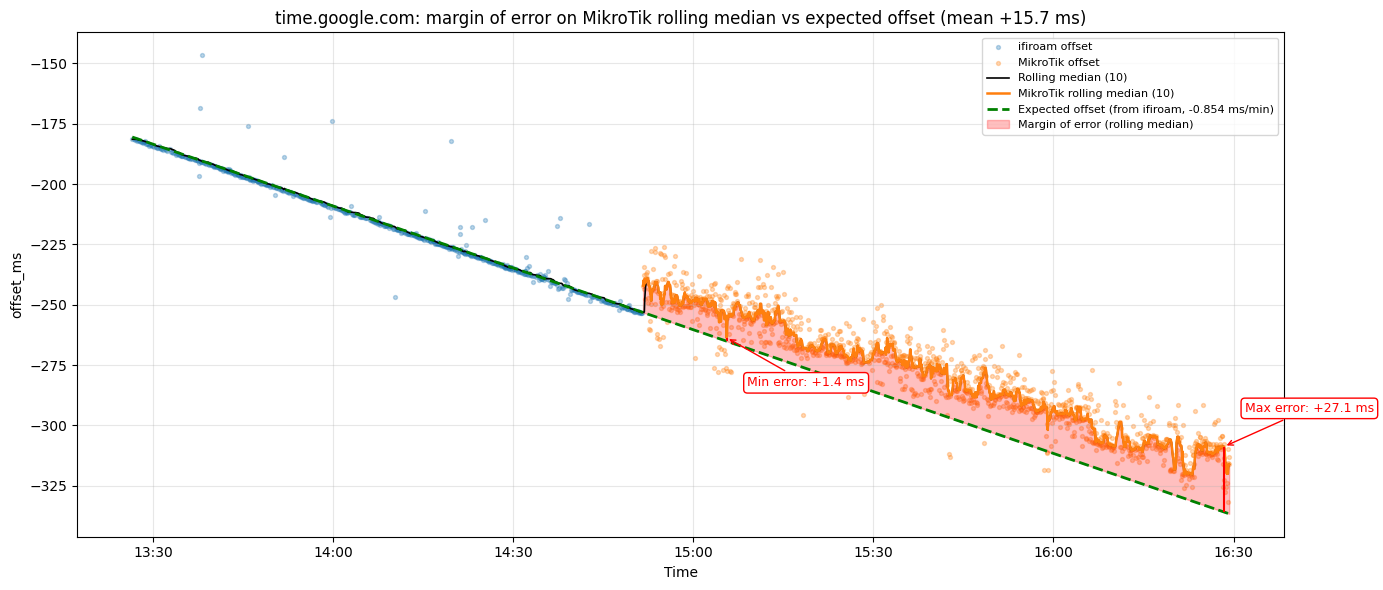

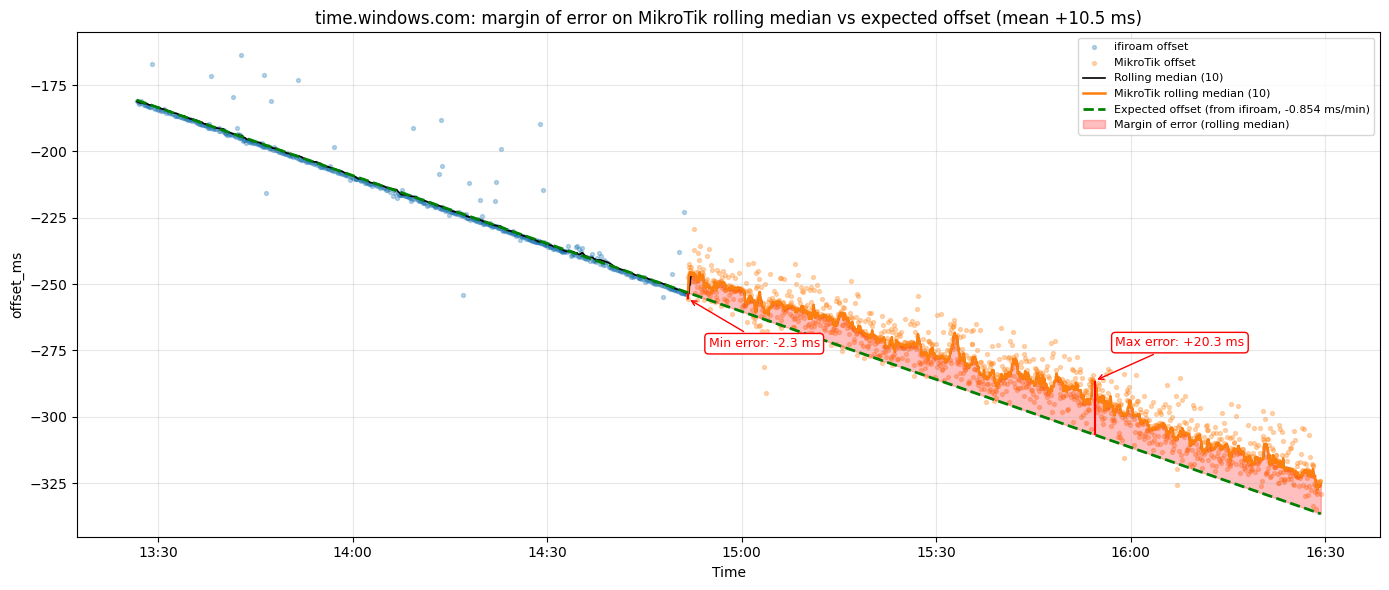

In [2]:
REF_NET = 'ifiroam'      # stable network used as reference
TEST_NET = 'MikroTik'    # network whose error is measured


def plot_margin(df, name):
    ok = df[df['is_success'] & df['offset_ms'].notna()].copy()
    ok['median'] = ok['offset_ms'].rolling(WINDOW, min_periods=1).median()
    ref = ok[ok['network_connection'].str.contains(REF_NET)]
    test = ok[ok['network_connection'].str.contains(TEST_NET)].copy()
    if ref.empty or test.empty:
        return
    # rolling median computed within the test network's own samples
    test['median'] = test['offset_ms'].rolling(WINDOW, min_periods=1).median()

    # imaginary line: linear trend of the reference rolling median, extrapolated forward
    x = lambda s: s.astype('int64') / 1e9 / 60  # minutes
    slope, icpt = np.polyfit(x(ref['time']), ref['median'], 1)
    ok['expected'] = slope * x(ok['time']) + icpt
    test['expected'] = slope * x(test['time']) + icpt
    test['error'] = test['median'] - test['expected']
    hi, lo = test.loc[test['error'].idxmax()], test.loc[test['error'].idxmin()]

    fig, ax = plt.subplots(figsize=(14, 6))
    ax.scatter(ref['time'], ref['offset_ms'], s=8, alpha=0.3, label=f'{REF_NET} offset')
    ax.scatter(test['time'], test['offset_ms'], s=8, alpha=0.3, color='tab:orange', label=f'{TEST_NET} offset')
    ax.plot(ok['time'], ok['median'], color='black', lw=1.2, label=f'Rolling median ({WINDOW})')
    ax.plot(test['time'], test['median'], color='tab:orange', lw=1.8,
            label=f'{TEST_NET} rolling median ({WINDOW})')
    ax.plot(ok['time'], ok['expected'], color='green', ls='--', lw=2,
            label=f'Expected offset (from {REF_NET}, {slope:.3f} ms/min)')
    ax.fill_between(test['time'], test['expected'], test['median'], color='red', alpha=0.25,
                    label='Margin of error (rolling median)')

    for row, tag in ((hi, 'Max'), (lo, 'Min')):
        ax.vlines(row['time'], row['expected'], row['median'], color='red', lw=1.5)
        ax.annotate(f"{tag} error: {row['error']:+.1f} ms", (row['time'], row['median']),
                    xytext=(15, 25 if tag == 'Max' else -35), textcoords='offset points',
                    arrowprops=dict(arrowstyle='->', color='red'), fontsize=9, color='red',
                    bbox=dict(boxstyle='round', fc='white', ec='red'))

    ax.set_title(f"{name}: margin of error on {TEST_NET} rolling median vs expected offset "
                 f"(mean {test['error'].mean():+.1f} ms)")
    ax.set_xlabel('Time')
    ax.set_ylabel('offset_ms')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz=TZ))
    ax.grid(alpha=0.3)
    ax.legend(loc='best', fontsize=8)
    fig.tight_layout()
    plt.show()


for f in sorted(DATA_DIR.glob('*.jsonl')):
    plot_margin(load(f), f.stem)
